In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, 
    classification_report,
    RocCurveDisplay)

In [11]:
df = pd.read_csv('deliriumwatch_clean.csv')
X = df.drop(columns=['delirium_label'])
y = df['delirium_label']

print("Features shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features shape: (57992, 31)
Target distribution:
delirium_label
0    36971
1    21021
Name: count, dtype: int64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42,stratify=y)
print(f"Train size: {X_train.shape[0]}")
print(f"Test size:  {X_test.shape[0]}")
print(f"\nTrain delirium rate: "
      f"{y_train.mean()*100:.1f}%")
print(f"Test delirium rate:  "
      f"{y_test.mean()*100:.1f}%")

Train size: 46393
Test size:  11599

Train delirium rate: 36.2%
Test delirium rate:  36.2%


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

AUROC: 0.8488

Classification Report:
              precision    recall  f1-score   support

 No Delirium       0.84      0.81      0.82      7395
    Delirium       0.68      0.72      0.70      4204

    accuracy                           0.78     11599
   macro avg       0.76      0.77      0.76     11599
weighted avg       0.78      0.78      0.78     11599



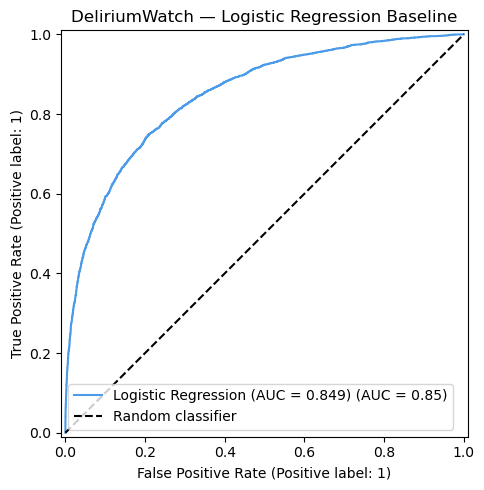

In [14]:
# Logistic Regression baseline
lr = LogisticRegression(
    class_weight='balanced',  # handles 64/36 imbalance
    max_iter=1000,            # enough iterations to converge
    random_state=42
)

lr.fit(X_train_scaled, y_train)

# Predict probabilities (not just 0/1)
# AUROC needs probabilities, not hard predictions
y_pred_proba = lr.predict_proba(X_test_scaled)[:, 1]
y_pred = lr.predict(X_test_scaled)

# Metrics
auroc = roc_auc_score(y_test, y_pred_proba)
print(f"AUROC: {auroc:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, 
      target_names=['No Delirium', 'Delirium']))

# ROC Curve
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(
    y_test, y_pred_proba,
    name=f"Logistic Regression (AUC = {auroc:.3f})",
    ax=ax, color='#4C9BE8'
)
ax.plot([0,1],[0,1],'k--', label='Random classifier')
ax.set_title('DeliriumWatch — Logistic Regression Baseline')
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=36971/21021,  # handles class imbalance
    random_state=42,
    eval_metric='auc',
    verbosity=0
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

y_pred_proba_xgb = xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb.predict(X_test)



In [17]:
auroc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
print(f"XGBoost AUROC: {auroc_xgb:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_xgb,
      target_names=['No Delirium', 'Delirium']))

XGBoost AUROC: 0.8689

Classification Report:
              precision    recall  f1-score   support

 No Delirium       0.86      0.80      0.83      7395
    Delirium       0.69      0.77      0.72      4204

    accuracy                           0.79     11599
   macro avg       0.77      0.78      0.78     11599
weighted avg       0.80      0.79      0.79     11599



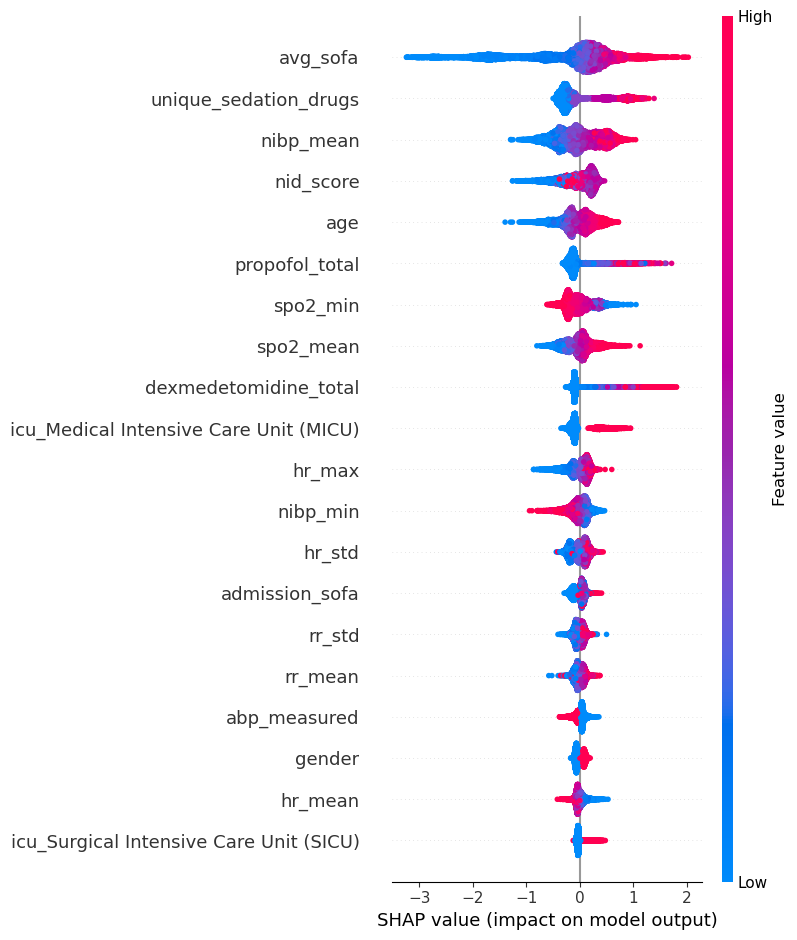

In [18]:
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)
plt.figure()
shap.summary_plot(
    shap_values, 
    X_test,
    feature_names=X.columns.tolist(),
    max_display=20,
    show=True
)

In [20]:
# Ablation study — model without NID
X_train_no_nid = X_train.drop(columns=['nid_score'])
X_test_no_nid = X_test.drop(columns=['nid_score'])

xgb_no_nid = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=36971/21021,
    random_state=42,
    eval_metric='auc',
    verbosity=0
)

xgb_no_nid.fit(X_train_no_nid, y_train)
y_pred_no_nid = xgb_no_nid.predict_proba(
    X_test_no_nid
)[:, 1]

auroc_no_nid = roc_auc_score(y_test, y_pred_no_nid)

print("=" * 45)
print(f"XGBoost WITH nid_score:    {auroc_xgb:.4f}")
print(f"XGBoost WITHOUT nid_score: {auroc_no_nid:.4f}")
print(f"NID contribution:          "
      f"+{auroc_xgb - auroc_no_nid:.4f} AUROC")
print("=" * 45)

XGBoost WITH nid_score:    0.8689
XGBoost WITHOUT nid_score: 0.8685
NID contribution:          +0.0004 AUROC


In [21]:
from scipy import stats

nid_delirious = X_test[y_test==1]['nid_score']
nid_not_delirious = X_test[y_test==0]['nid_score']

t_stat, p_value = stats.mannwhitneyu(
    nid_delirious, 
    nid_not_delirious,
    alternative='greater'
)

print(f"NID score — delirious patients:")
print(f"  Mean: {nid_delirious.mean():.4f}")
print(f"  Median: {nid_delirious.median():.4f}")
print(f"\nNID score — non-delirious patients:")
print(f"  Mean: {nid_not_delirious.mean():.4f}")
print(f"  Median: {nid_not_delirious.median():.4f}")

print(f"\nMann-Whitney U test:")
print(f"  p-value: {p_value:.6f}")
print(f"  Statistically significant: {p_value < 0.05}")

NID score — delirious patients:
  Mean: 0.3250
  Median: 0.3266

NID score — non-delirious patients:
  Mean: 0.3087
  Median: 0.3074

Mann-Whitney U test:
  p-value: 0.000000
  Statistically significant: True
